In [5]:
# --- Bloc à mettre au DÉBUT du NOUVEAU notebook ---
import pandas as pd
import numpy as np
import os

# Configuration des chemins
DATA_PATH = "/home/kaoutar/Desktop/data/"
OUTPUT_PATH = DATA_PATH
ENHANCED_FEATURES_FILE = os.path.join(OUTPUT_PATH, 'X_fe_enhanced_110cols.parquet') # Adapter si CSV utilisé
TARGET_FILE = os.path.join(OUTPUT_PATH, 'y_fe_enhanced_target.csv')

print("Chargement des features enrichies X_fe et de la cible y_fe...")

if os.path.exists(ENHANCED_FEATURES_FILE) and os.path.exists(TARGET_FILE):
    try:
        # Charger Parquet :
        X_fe = pd.read_parquet(ENHANCED_FEATURES_FILE)
        # Ou charger CSV si sauvegardé en CSV :
        # X_fe = pd.read_csv(ENHANCED_FEATURES_FILE, sep=',')

        # Charger la cible (Series depuis CSV)
        y_fe = pd.read_csv(TARGET_FILE, sep=',').squeeze("columns") # squeeze pour obtenir une Series

        print(f"Chargement réussi. Shape X_fe: {X_fe.shape}, Shape y_fe: {y_fe.shape}")
        # Afficher un aperçu
        print("Aperçu X_fe chargé :")
        display(X_fe.head())

    except Exception as e:
        print(f"ERREUR lors du chargement des fichiers sauvegardés: {e}")
        X_fe = None
        y_fe = None
else:
    print(f"ERREUR: Fichiers {ENHANCED_FEATURES_FILE} ou {TARGET_FILE} non trouvés.")
    X_fe = None
    y_fe = None

# Vérifier que les variables sont chargées avant de continuer
if X_fe is None or y_fe is None:
    raise RuntimeError("Erreur lors du chargement des données enrichies nécessaires pour la suite.")
# ----------------------------------------------------

# MAINTENANT, vous pouvez coller et exécuter les blocs pour :
# 1. La Sélection Stricte sur X_fe -> création de X_final_ready, y_final_ready
# 2. Les Étapes V et VI sur X_final_ready, y_final_ready

Chargement des features enrichies X_fe et de la cible y_fe...
Chargement réussi. Shape X_fe: (1051281, 113), Shape y_fe: (1051281,)
Aperçu X_fe chargé :


,age,customer_tenure_years,solde_m,solde_std,solde_med,mvtcred_m,mvtdeb_m,mvtcred_tot,mvtdeb_tot,nbmvtc_m,...,age_group_66-75,age_group_75+,ratio_debit_credit_tot,avg_amount_per_ops_agence,avg_amount_per_credit,age^2,age customer_tenure_years,customer_tenure_years^2,age_x_profil_senior,tenure_x_profil_newmigrant
0,50.1,3.7,112377.532857,9.203614e+04,97868.00,57334.560000,75768.908571,401341.92,530382.36,2.142857,...,0,0,1.321522,15922.000000,0.0,2510.01,185.37,13.69,0.0,0.0
1,45.3,3.7,4512.861667,1.122064e+04,-52.48,0.000000,17.806667,0.00,106.84,0.000000,...,0,0,0.000000,11250.000000,0.0,2052.09,167.61,13.69,0.0,0.0
2,56.3,3.6,876801.000000,1.225842e+06,876801.00,0.000000,0.000000,0.00,0.00,0.000000,...,0,0,0.000000,196130.285714,0.0,3169.69,202.68,12.96,0.0,0.0
3,74.3,3.5,50793.980000,1.851919e+04,50124.68,14500.000000,8552.285000,58000.00,34209.14,0.750000,...,1,0,0.589813,3566.666667,0.0,5520.49,260.05,12.25,74.3,0.0
4,39.1,3.5,205.030000,1.828305e+02,204.48,63.688333,13.200000,382.13,79.20,0.166667,...,0,0,0.207259,0.000000,0.0,1528.81,136.85,12.25,0.0,0.0


In [6]:
# --- Étape Suivante: Sélection Stricte sur Features Enrichies (X_fe) ---
print("\n--- Application de la Sélection Stricte (Objectif A) sur X_fe Enrichi ---")

# S'assurer que X_fe et y_fe existent (normalement créés par le bloc précédent)
if 'X_fe' in locals() and 'y_fe' in locals() and isinstance(X_fe, pd.DataFrame) and not X_fe.empty:

    # Définir la liste STRICTE des colonnes "leaky" à retirer
    # (Utilise les noms exacts présents dans X_fe - SANS les préfixes)
    # Cette liste est basée sur la définition ORIGINALE de appetent (Abonnement ET Action)
    cols_to_remove_strict_exact_names = [
        # Flags finaux liés à la définition originale (s'ils existent encore dans X_fe)
        'has_transaction', 'used_getchq', 'paid_vignette', 'validated_subscription', 'connected',
        # Agrégats Transa
        'dig_montant_m', 'dig_montant_tot', 'dig_nb_op_tot', 'dig_nb_sessions', 'dig_nb_type_ope_distinct',
        # Agrégats Getchq
        'getchq_count',
        # Agrégats Vignette
        'vignette_count', 'vignette_montant_m', 'vignette_montant_tot',
        # Agrégats Equi
        'is_sub_valid',
        # Agrégats Connexion
        'connect_count_raw', 'connect_different_dates', 'connect_ever_success', 'connect_locked'
        # Ajouter ici les colonnes _days_since_last si elles existent dans X_fe et sont jugées leaky
        # (Ex: 'transa_days_since_last', 'getchq_days_since_last', ...)
        # Vérifiez X_fe.columns pour voir si elles existent
    ]
    # Ajouter les colonnes _days_since_last si elles existent dans X_fe
    days_since_cols_leaky = [col for col in X_fe.columns if col.endswith('_days_since_last')]
    if days_since_cols_leaky:
         print(f"  Ajout des colonnes days_since_last à la liste de suppression: {days_since_cols_leaky}")
         cols_to_remove_strict_exact_names.extend(days_since_cols_leaky)

    # Retirer seulement les colonnes qui existent dans X_fe
    cols_actually_in_X_to_remove = list(set([col for col in cols_to_remove_strict_exact_names if col in X_fe.columns]))
    print(f"Colonnes 'leaky' à retirer de X_fe: {len(cols_actually_in_X_to_remove)}")
    print(f"Liste retirée (extrait): {sorted(cols_actually_in_X_to_remove)[:15]}...") # Afficher les 15 premières

    # Créer le jeu de features final assaini ET enrichi
    features_cleaned_enhanced = [col for col in X_fe.columns if col not in cols_actually_in_X_to_remove]

    if not features_cleaned_enhanced:
         raise ValueError("ERREUR: Aucune feature ne reste après la sélection stricte sur X_fe!")
    else:
         # --- Création des variables finales pour la modélisation ---
         X_final_ready = X_fe[features_cleaned_enhanced].copy()
         y_final_ready = y_fe.copy() # Utiliser y_fe qui correspond à X_fe
         # ---------------------------------------------------------

         print(f"\nJeu de features final assaini et enrichi (X_final_ready) créé.")
         # Le nombre de colonnes devrait être ~110 - len(cols_actually_in_X_to_remove)
         print(f"Nouvelle Shape pour Modélisation (Objectif A): {X_final_ready.shape}")

         print("\nPRÊT POUR LES ÉTAPES SUIVANTES (V et VI) :")
         print("1. Exécuter l'Étape V (Split, SMOTE, Scale) sur X_final_ready et y_final_ready.")
         print("2. Exécuter l'Étape VI (Train, Evaluate) sur les données préparées.")
         print("3. Comparer les performances avec le modèle précédent (sur 78 features non enrichies).")

else:
    print("ERREUR: DataFrame X_fe non trouvé ou vide. Impossible de faire la sélection.")
    # Assigner des valeurs vides pour éviter erreurs si on enchaîne direct
    X_final_ready = pd.DataFrame()
    y_final_ready = pd.Series()


--- Application de la Sélection Stricte (Objectif A) sur X_fe Enrichi ---
Colonnes 'leaky' à retirer de X_fe: 19
Liste retirée (extrait): ['connect_count_raw', 'connect_different_dates', 'connect_ever_success', 'connect_locked', 'connected', 'dig_montant_m', 'dig_montant_tot', 'dig_nb_op_tot', 'dig_nb_sessions', 'dig_nb_type_ope_distinct', 'getchq_count', 'has_transaction', 'is_sub_valid', 'paid_vignette', 'used_getchq']...

Jeu de features final assaini et enrichi (X_final_ready) créé.
Nouvelle Shape pour Modélisation (Objectif A): (1051281, 94)

PRÊT POUR LES ÉTAPES SUIVANTES (V et VI) :
1. Exécuter l'Étape V (Split, SMOTE, Scale) sur X_final_ready et y_final_ready.
2. Exécuter l'Étape VI (Train, Evaluate) sur les données préparées.
3. Comparer les performances avec le modèle précédent (sur 78 features non enrichies).



--- ÉTAPE V: Préparation Avant Modélisation (sur Données Assainies et Enrichies) ---
Utilisation de X_final_ready (Shape: (1051281, 94)) et y_final_ready.

Séparation Train/Test (80/20)...
  Shapes - Train: (841024, 94), Test: (210257, 94)
  Distribution Cible Train:
appetent
0    92.396769
1     7.603231
Name: proportion, dtype: float64
  Distribution Cible Test:
appetent
0    92.396924
1     7.603076
Name: proportion, dtype: float64

Application de SMOTE sur les données d'entraînement...
  Shape Train après SMOTE: (1554158, 94)
  Distribution Cible Train après SMOTE:
appetent
0    50.0
1    50.0
Name: proportion, dtype: float64

Mise à l'échelle (StandardScaler)...
  Scaling des colonnes (39): ['age', 'customer_tenure_years', 'solde_m', 'solde_std', 'solde_med']...
  Scaling appliqué.

--- ÉTAPE VI: Entraînement et Évaluation (sur Données Assainies et Enrichies) ---

Entraînement RandomForest Final...
  Entraînement terminé.

Évaluation sur le jeu de Test:

Classification Report (Te

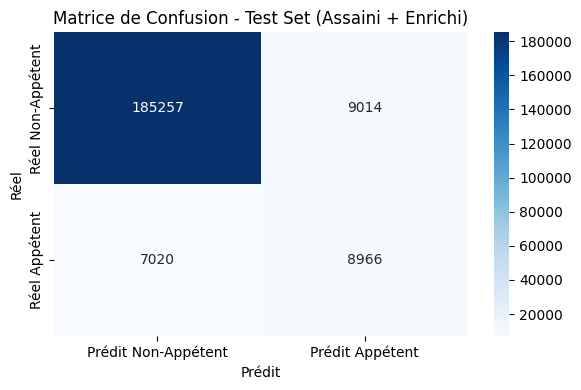


AUC ROC (Test): 0.9204
AUC PR (Test): 0.5459


In [7]:
# =============================================================================
# ÉTAPE V : PRÉPARATION AVANT MODÉLISATION (sur X_final_ready assaini et enrichi)
# =============================================================================
from sklearn.model_selection import train_test_split
# Manipulation de données
import pandas as pd
import numpy as np

# Système d'exploitation et dates/temps
import os
from datetime import datetime
import re # Pour expressions régulières (nettoyage noms colonnes)

# Visualisation (si vous décommentez/utilisez les plots)
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning - Préparation et Sélection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures # MinMaxScaler pour check chi2, PolynomialFeatures si utilisé en FE
from sklearn.feature_selection import SelectKBest, chi2, f_classif

# Machine Learning - Rééquilibrage
# Assurez-vous d'avoir installé imblearn: pip install imbalanced-learn
from imblearn.over_sampling import SMOTE

# Machine Learning - Modèle
from sklearn.ensemble import RandomForestClassifier

# Machine Learning - Métriques d'évaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    auc
)




print("\n--- ÉTAPE V: Préparation Avant Modélisation (sur Données Assainies et Enrichies) ---")

# Vérifier que les variables existent et ne sont pas vides
if ('X_final_ready' in locals() and 'y_final_ready' in locals() and
    isinstance(X_final_ready, pd.DataFrame) and not X_final_ready.empty and
    isinstance(y_final_ready, pd.Series) and not y_final_ready.empty):

    print(f"Utilisation de X_final_ready (Shape: {X_final_ready.shape}) et y_final_ready.")

    # 1. Séparation Train/Test
    print("\nSéparation Train/Test (80/20)...")
    # Utiliser les variables finales X_final_ready et y_final_ready
    X_train, X_test, y_train, y_test = train_test_split(X_final_ready, y_final_ready,
                                                        test_size=0.2,
                                                        random_state=42,
                                                        stratify=y_final_ready)
    print(f"  Shapes - Train: {X_train.shape}, Test: {X_test.shape}")
    print(f"  Distribution Cible Train:\n{y_train.value_counts(normalize=True)*100}")
    print(f"  Distribution Cible Test:\n{y_test.value_counts(normalize=True)*100}")

    # 2. Gestion du Déséquilibre (SMOTE sur Train)
    print("\nApplication de SMOTE sur les données d'entraînement...")
    smote = SMOTE(random_state=42) # Appel CORRIGÉ
    try:
        # Vérifier et remplir NaNs avant SMOTE (sécurité ultime)
        if X_train.isna().sum().sum() > 0:
             print("  ATTENTION: NaNs détectés dans X_train avant SMOTE. Remplissage par la médiane...")
             X_train = X_train.fillna(X_train.median())
        X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
        print(f"  Shape Train après SMOTE: {X_train_resampled.shape}")
        print(f"  Distribution Cible Train après SMOTE:\n{pd.Series(y_train_resampled).value_counts(normalize=True)*100}")
    except Exception as e:
        print(f"  ERREUR pendant SMOTE: {e}. Utilisation des données originales.")
        X_train_resampled, y_train_resampled = X_train, y_train # Fallback

    # 3. Mise à l'échelle (Scaling)
    print("\nMise à l'échelle (StandardScaler)...")
    # Identifier numériques sur X_final_ready (floats + potentiellement ints non binaires)
    numerical_cols_to_scale = X_final_ready.select_dtypes(include=np.number).columns
    # Exclure les colonnes qui sont essentiellement binaires (0/1) même si int
    # aussi exclure les colonnes one-hot des groupes d'âge si créées
    binary_cols = [col for col in X_final_ready.select_dtypes(include='int').columns if X_final_ready[col].nunique() <= 2]
    age_group_cols = [col for col in X_final_ready.columns if col.startswith('age_group_')]
    cols_to_exclude_from_scaling = binary_cols + age_group_cols
    numerical_cols_to_scale = [c for c in numerical_cols_to_scale if c not in cols_to_exclude_from_scaling and c in X_train_resampled.columns] # Check existence

    if numerical_cols_to_scale:
         scaler = StandardScaler()
         # Créer copies pour éviter de modifier les dataframes originaux resamplés/test
         X_train_scaled = X_train_resampled.copy()
         X_test_scaled = X_test.copy()
         # Remplir les NaN dans X_test avant transform (sécurité ultime, utiliser médiane de train)
         if X_test_scaled[numerical_cols_to_scale].isna().sum().sum() > 0:
              print("  ATTENTION: NaNs détectés dans X_test avant scaling. Remplissage par la médiane de train...")
              test_fill_values = X_train[numerical_cols_to_scale].median() # Utiliser médiane de train original
              # Assigner en utilisant .loc pour éviter SettingWithCopyWarning
              X_test_scaled.loc[:, numerical_cols_to_scale] = X_test_scaled[numerical_cols_to_scale].fillna(test_fill_values)

         print(f"  Scaling des colonnes ({len(numerical_cols_to_scale)}): {numerical_cols_to_scale[:5]}...") # Afficher les 5 premières
         # Fitter sur Train (resampled) et transformer
         X_train_scaled.loc[:, numerical_cols_to_scale] = scaler.fit_transform(X_train_scaled[numerical_cols_to_scale])
         # Transformer sur Test
         X_test_scaled.loc[:, numerical_cols_to_scale] = scaler.transform(X_test_scaled[numerical_cols_to_scale])
         print("  Scaling appliqué.")
    else:
         print("  Aucune colonne numérique non-binaire à scaler trouvée.")
         X_train_scaled = X_train_resampled.copy()
         X_test_scaled = X_test.copy()
else:
    print("Erreur: X_final_ready ou y_final_ready non définis ou vides pour l'étape V.")
    # Assigner des vides pour que la cellule suivante ne plante pas si exécutée à la suite
    X_train_scaled, X_test_scaled, y_train_resampled, y_test = None, None, None, None


# =============================================================================
# ÉTAPE VI : ENTRAÎNEMENT ET ÉVALUATION (sur données assainies ET enrichies)
# =============================================================================
print("\n--- ÉTAPE VI: Entraînement et Évaluation (sur Données Assainies et Enrichies) ---")

# Vérifier si les variables nécessaires existent et ne sont pas vides
if (isinstance(X_train_scaled, pd.DataFrame) and not X_train_scaled.empty and
    isinstance(y_train_resampled, pd.Series) and not y_train_resampled.empty and
    isinstance(X_test_scaled, pd.DataFrame) and not X_test_scaled.empty and
    isinstance(y_test, pd.Series) and not y_test.empty):

    print("\nEntraînement RandomForest Final...")
    # Utiliser les mêmes hyperparamètres que le test précédent pour comparer
    rf_final_model = RandomForestClassifier(n_estimators=100,
                                          random_state=42,
                                          n_jobs=-1,
                                          class_weight=None, # SMOTE gère l'équilibre
                                          max_depth=15,
                                          min_samples_leaf=5)

    rf_final_model.fit(X_train_scaled, y_train_resampled)
    print("  Entraînement terminé.")

    print("\nÉvaluation sur le jeu de Test:")
    y_pred_test = rf_final_model.predict(X_test_scaled)
    y_proba_test = rf_final_model.predict_proba(X_test_scaled)[:, 1] # Probabilité classe 1

    print("\nClassification Report (Test - Données Assainies et Enrichies):")
    # --- Analyser ces scores réalistes ---
    print(classification_report(y_test, y_pred_test, zero_division=0))

    print("\nMatrice de Confusion (Test - Données Assainies et Enrichies):")
    cm = confusion_matrix(y_test, y_pred_test)
    print(cm)
    try: # Affichage graphique
        plt.figure(figsize=(6,4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Prédit Non-Appétent', 'Prédit Appétent'],
                    yticklabels=['Réel Non-Appétent', 'Réel Appétent'])
        plt.xlabel('Prédit')
        plt.ylabel('Réel')
        plt.title('Matrice de Confusion - Test Set (Assaini + Enrichi)')
        plt.tight_layout()
        plt.show()
    except Exception as e: print(f"  Erreur affichage heatmap: {e}")

    # Calcul et affichage des métriques clés
    try:
         roc_auc = roc_auc_score(y_test, y_proba_test)
         print(f"\nAUC ROC (Test): {roc_auc:.4f}")
    except ValueError as e: print(f"  Impossible de calculer AUC ROC: {e}")

    try:
         precision, recall, _ = precision_recall_curve(y_test, y_proba_test)
         pr_auc = auc(recall, precision)
         print(f"AUC PR (Test): {pr_auc:.4f}") # Métrique clé
    except ValueError as e: print(f"  Impossible de calculer AUC PR: {e}")

else:
    print("Erreur: Données d'entraînement/test non disponibles ou vides pour l'étape VI.")